# Self-admitted ChatGPT / Copilot code on GitHub
**Paper:** Yu et al. 2024 – Where Are Large Language Models for Code Generation in GitHub?
**Data:** https://github.com/lkpttxg/WhereCodeGenerationByLLM

**What is in the data:** Files whose comments say the code was **generated by ChatGPT, GPT-4 or Copilot** (5 languages), with what happened to them later: how many later commits, how many **fix commits**, and the type of change.

**One row of the main table =** one file with self-admitted LLM code

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "../..")          # to find common.py in the parent folder
from common import *

## 0. Get the data

In [2]:
root = get_repo("https://github.com/lkpttxg/WhereCodeGenerationByLLM", "wherecodegenerationbyllm")

Data folder: ../../data/05_Yu_ChatGPT_Copilot/wherecodegenerationbyllm


## 1. First look
### Files in the repository

In [3]:
list_files(root).head(20)

,file,size_MB
0,results-code-change-type/python-code-change-type.xlsx,0.36
1,results-code-change-type/javascript-code-change-type.xlsx,0.21
2,results-code-change-type/java-code-change-type.xlsx,0.12
3,results-code-change-type/cpp-code-change-type.xlsx,0.12
4,results-code-change-type/typescript-code-change-type.xlsx,0.07


### Main table: one sheet per language, put together

In [4]:
import glob
parts = []
for f in glob.glob(os.path.join(root, "results-code-change-type", "*-code-change-type.xlsx")):
    t = pd.read_excel(f); t["language"] = os.path.basename(f).split("-")[0]; parts.append(t)
y = pd.concat(parts, ignore_index=True)
_ = overview(y, "LLM-generated files")

**LLM-generated files** — **1,413 rows × 89 columns** (1.7 MB in memory)

*First 5 lines:*

,index,project_name,create_time,project_language,contributor,star,fork,issues,watch,project_commits,code_language,keyword_index,matched_keyword,path_of_first_file_commit,file_first_commit,code_change_type,final_change_commit_path,code_granularity_data,code_func_type,number_of_bug_or_vulnerability_all_commit,comments,start_end_line_data,first_loc,final_start_end_line_data,final_loc_add,...,project_complexity_mean_method,project_cognitive_complexity_mean_method,code_lines,code_locs,code_statements,code_functions,code_classes,code_files,code_density_comments,code_comments,code_duplicated_lines,code_duplicated_blocks,code_duplicated_files,code_duplicated_lines_density,code_code_smells,code_sqale_index,code_sqale_debt_ratio,code_complexity_all,code_cognitive_complexity_all,code_complexity_mean_method,code_cognitive_complexity_mean_method,manual_vs_gpt_loc_ratio,manual_vs_gpt_change_commit_ratio,manual_vs_gpt_change_fix_commit_ratio,language
0,130,team-panda,2023-02-21 05:12:00,Java,3.0,0,1,5,1,140,Java,13,generated by chatgpt,team-panda\cca3c72eda35f0d86ee7e289b697853f34cf85ef\src\...,team-panda\cca3c72eda35f0d86ee7e289b697853f34cf85ef\src\...,Refactoring,team-panda\616974fdd7e44c231568a627435091dfa899afcc\src\...,method,NaN,8,NaN,"[13,18]",6,"[13,18]",0.0,...,1.21,0.31,7,6,3,1,1,1,11.1,1,0,0,0,0.0,2,15,6.3,1,0,1.00,0.00,NaN,NaN,NaN,java
1,9,Team1_G3,2024-03-06 18:53:00,Java,4.0,0,0,0,1,91,Java,221,created by chatgpt,Team1_G3\159687a2d6b08f0978f1e03fe828663117d1e3e7\src\ma...,Team1_G3\159687a2d6b08f0978f1e03fe828663117d1e3e7\src\ma...,Refactoring,Team1_G3\c35712a3233cdc7fd5e42cc99764acacc45c205e\src\ma...,method,NaN,5,NaN,"[220,310]",91,"[22,112]",0.0,...,1.90,0.53,92,85,77,1,1,1,1.1,1,0,0,0,0.0,9,95,3.6,1,0,1.00,0.00,NaN,NaN,NaN,java
2,19,Team1_G3,2024-03-06 18:53:00,Java,4.0,0,0,0,1,91,Java,221,created by chatgpt,Team1_G3\159687a2d6b08f0978f1e03fe828663117d1e3e7\src\ma...,Team1_G3\159687a2d6b08f0978f1e03fe828663117d1e3e7\src\ma...,Refactoring,Team1_G3\c35712a3233cdc7fd5e42cc99764acacc45c205e\src\ma...,method,NaN,5,NaN,"[220,310]",91,"[22,112]",0.0,...,1.90,0.53,92,85,77,1,1,1,1.1,1,0,0,0,0.0,9,95,3.6,1,0,1.00,0.00,NaN,NaN,NaN,java
3,17,SyntaxSorcerers,2023-10-04 20:06:00,JavaScript,4.0,0,2,25,3,172,Java,18,generated with chatgpt,SyntaxSorcerers\52a56c504d759424e78fbf465dd530f10b5badc1...,SyntaxSorcerers\52a56c504d759424e78fbf465dd530f10b5badc1...,Refactoring,SyntaxSorcerers\f594cef2246ad9899dfc5b9227b51df9ee8162d3...,file,NaN,38,NaN,"[1,107]",107,"[1,33]",0.0,...,2.66,1.79,107,77,20,7,4,1,7.2,6,0,0,0,0.0,1,2,0.1,9,6,1.29,0.86,NaN,NaN,NaN,java
4,64,project-team-31,2024-01-31 05:00:00,Java,6.0,0,0,1,1,142,Java,63,generated by chatgpt,project-team-31\c0aeb8b9578ce30f9665c18dd74add58037ffff4...,project-team-31\c0aeb8b9578ce30f9665c18dd74add58037ffff4...,Refactoring,project-team-31\1c401944a30c2e763d35e6063705b9441e71dd1a...,method,NaN,30,NaN,"[64,88]",25,"[66,88]",0.0,...,1.13,0.28,26,17,6,4,1,1,13.6,3,0,0,0,0.0,2,15,2.6,1,0,0.25,0.00,NaN,NaN,NaN,java


*All columns:*

,column,type,missing_%,unique,example
0,index,int64,0.0,706,130
1,project_name,str,0.0,977,team-panda
2,create_time,datetime64[us],0.0,1019,2023-02-21 05:12:00
3,project_language,str,0.1,37,Java
4,contributor,float64,61.4,41,3.0
...,...,...,...,...,...
84,code_cognitive_complexity_mean_method,float64,0.0,142,0.0
85,manual_vs_gpt_loc_ratio,float64,100.0,0,
86,manual_vs_gpt_change_commit_ratio,float64,100.0,0,
87,manual_vs_gpt_change_fix_commit_ratio,float64,100.0,0,


## 2. Data-science view
### Size and dates

In [5]:
y["tool"] = y["matched_keyword"].map(agent_of)
y["changed_later"] = pd.to_numeric(y["number_of_all_change_commit"], errors="coerce").fillna(0) > 0
y["fix_commits"] = pd.to_numeric(y["number_of_all_change_fix_commit"], errors="coerce").fillna(0)
y["create_time"] = pd.to_datetime(y["create_time"], errors="coerce", utc=True)
print("Files:", len(y), "| projects:", y.project_name.nunique())
print(y.language.value_counts().to_dict())
print("Project creation dates:", y.create_time.min().date(), "->", y.create_time.max().date())

Files: 1413 | projects: 977
{'python': 660, 'javascript': 349, 'java': 174, 'cpp': 151, 'typescript': 79}
Project creation dates: 2023-02-01 -> 2024-05-14


### Numbers per AI tool (from the keyword in the comment)

In [6]:
per_agent = y.groupby("tool").agg(files=("project_name", "size"), projects=("project_name", "nunique"),
            changed_later=("changed_later", "sum"), files_with_fix=("fix_commits", lambda s: (s > 0).sum()), fix_commits=("fix_commits", "sum"))
per_agent["files_with_fix_%"] = (100 * per_agent["files_with_fix"] / per_agent["files"]).round(1)
per_agent = per_agent.sort_values("files", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,files,projects,changed_later,files_with_fix,fix_commits,files_with_fix_%
tool,,,,,,
ChatGPT,935,699,263,85,163,9.1
GPT-4,247,105,30,6,10,2.4
Copilot,165,137,50,19,36,11.5
GPT-3,66,42,6,3,10,4.5


### How the agent is involved
The developer **pastes code generated by the tool** and writes it in a comment (*generated by ChatGPT*…). Later commits are made by the **developers** (the data does not say who exactly).

In [7]:
inv = y.groupby("language").agg(files=("tool", "size"), changed_later=("changed_later", "sum"), files_with_fix=("fix_commits", lambda s: (s > 0).sum()))
save_table(inv.reset_index(), "per_language")
inv

,files,changed_later,files_with_fix
language,,,
cpp,151,42,19
java,174,42,8
javascript,349,95,26
python,660,146,53
typescript,79,24,7


In [8]:
summary_card("Yu et al. 2024", "file with self-admitted LLM code", len(y), y.project_name.nunique(), str(y.create_time.min().date()),
             str(y.create_time.max().date()), ", ".join(per_agent.index), "Developer pastes LLM code (comment says so); later changes by developers",
             int((y.fix_commits > 0).sum()))

,
paper,Yu et al. 2024
unit (1 row =),file with self-admitted LLM code
rows,1413
repos,977
first date,2023-02-01
latest date,2024-05-14
agents,"ChatGPT, GPT-4, Copilot, GPT-3"
how the agent is involved,Developer pastes LLM code (comment says so); later chang...
fixes of AI code,113


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Yu et al. 2024,file with self-admitted LLM code,1413,977,2023-02-01,2024-05-14,"ChatGPT, GPT-4, Copilot, GPT-3",Developer pastes LLM code (comment says so); later chang...,113


## 3. Charts
### Chart 1 · What kind of change was made later

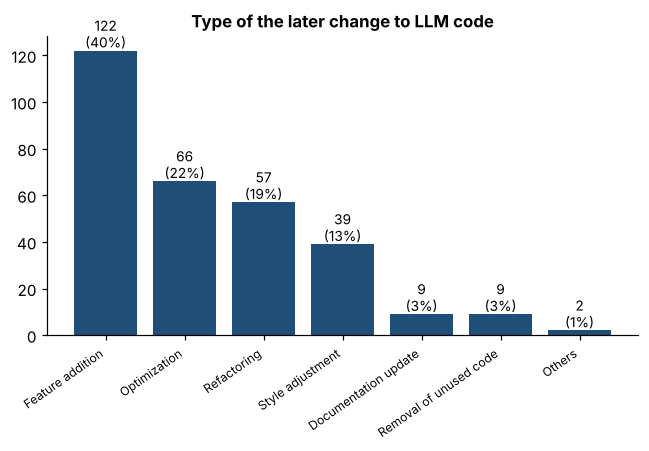

*Exact numbers – Type of the later change to LLM code*

,number,%
code_change_type,,
Feature addition,122.0,40.1
Optimization,66.0,21.7
Refactoring,57.0,18.8
Style adjustment,39.0,12.8
Documentation update,9.0,3.0
Removal of unused code,9.0,3.0
Others,2.0,0.7
TOTAL,304.0,100.0


In [9]:
ct = y["code_change_type"].dropna().astype(str).str.split(",").explode().str.strip()
bar(ct.value_counts(), "Type of the later change to LLM code", "1_change_types.png", horizontal=True, pct=True)

### Chart 2 · Files with fix commits, per AI tool

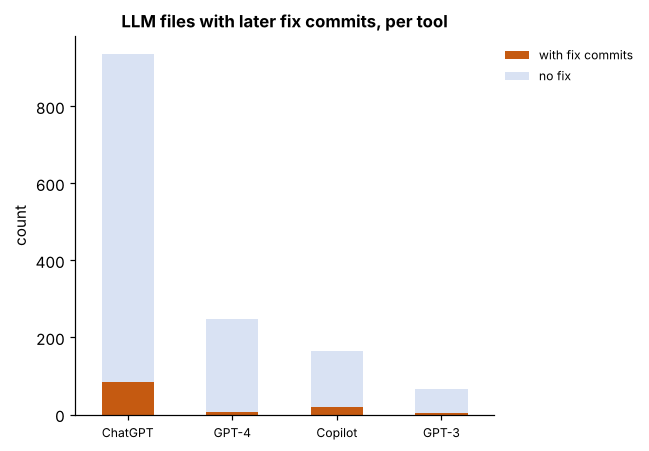

*Exact numbers – LLM files with later fix commits, per tool*

,with fix commits,no fix,TOTAL
tool,,,
GPT-3,3,63,66
Copilot,19,146,165
GPT-4,6,241,247
ChatGPT,85,850,935
TOTAL,113,1300,1413


In [10]:
stacked(pd.DataFrame({"with fix commits": per_agent["files_with_fix"], "no fix": per_agent["files"] - per_agent["files_with_fix"]}).iloc[::-1], "LLM files with later fix commits, per tool", "2_fix_per_tool.png", colors=[ORANGE, LIGHT])

### Chart 3 · Who wrote the fix
Not in the data (all later commits are by the project developers). Instead: what happened to the files, per language.

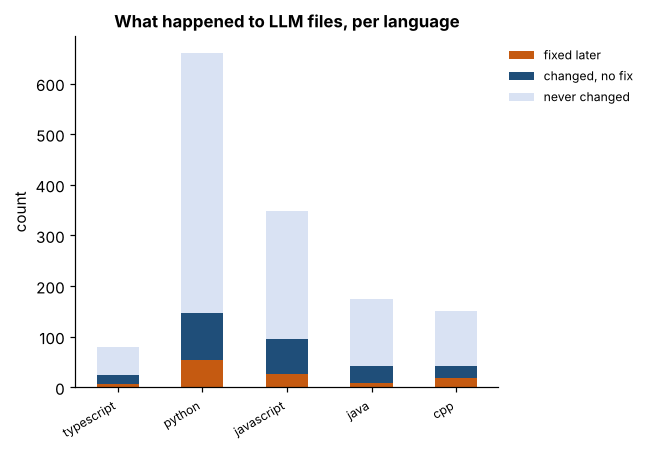

*Exact numbers – What happened to LLM files, per language*

,fixed later,"changed, no fix",never changed,TOTAL
language,,,,
cpp,19,23,109,151
java,8,34,132,174
javascript,26,69,254,349
python,53,93,514,660
typescript,7,17,55,79
TOTAL,113,236,1064,1413


In [11]:
stacked(pd.DataFrame({"fixed later": inv["files_with_fix"], "changed, no fix": inv["changed_later"] - inv["files_with_fix"], "never changed": inv["files"] - inv["changed_later"]}).clip(lower=0), "What happened to LLM files, per language", "3_outcome_per_language.png", colors=[ORANGE, BLUE, LIGHT])

### Chart 4 · How fast the change comes
No dates of the changes in the data; we use the **number of commits until the first change**.

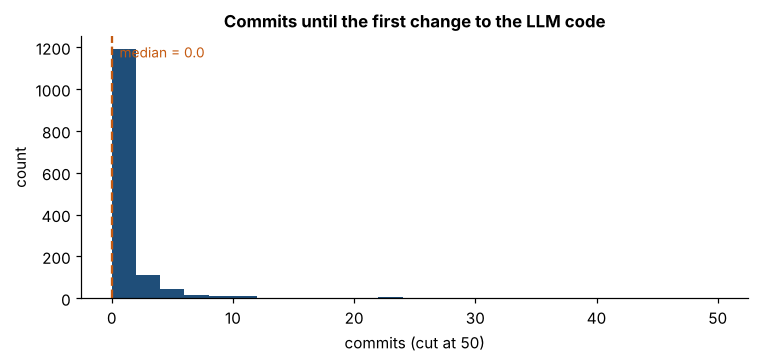

*Exact numbers – Commits until the first change to the LLM code*

,count,mean,std,min,25%,median,75%,max
commits (cut at 50),1413.0,1.11,4.0,0.0,0.0,0.0,0.0,50.0


In [12]:
hist(pd.to_numeric(y["number_of_change_commit_to_first"], errors="coerce").clip(upper=50), "Commits until the first change to the LLM code", "4_commits_to_first_change.png", "commits (cut at 50)", bins=25)

## 4. Final figure (the 4 charts on one page)

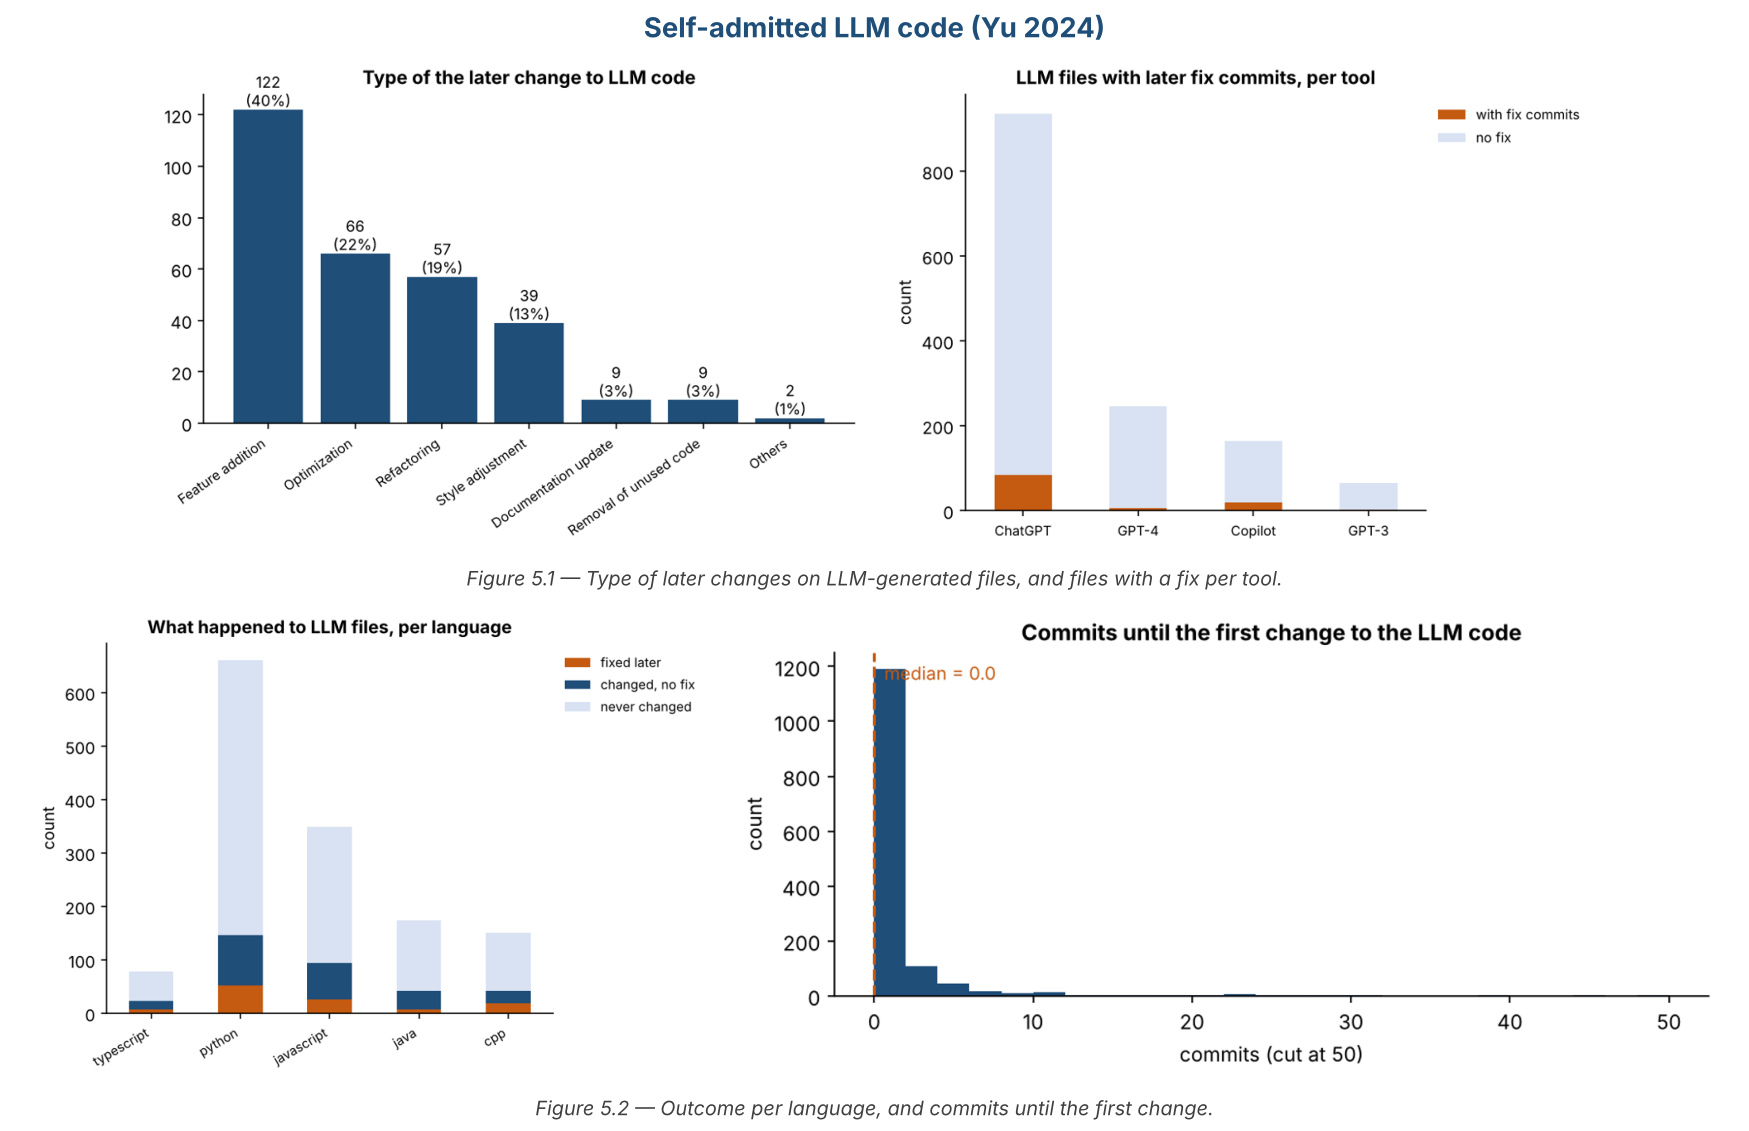

In [13]:
final_figure(5, "Self-admitted LLM code (Yu 2024)",
             "Type of later changes on LLM-generated files, and files with a fix per tool.",
             "Outcome per language, and commits until the first change.")

## 5. The fixes in one common format
Each row = one **file with LLM code that later got fix commits** (the hash and reason of the real fix are kept when the paper gives them).

The notebook `99_ALL_PAPERS_summary` merges this file from every paper into the **final dataset**.

In [14]:
a = y[y.fix_commits > 0]
f = pd.DataFrame({"agent": a["tool"], "repo": a["project_name"],
    "language": a["code_language"].astype(str).str.capitalize().replace({"Cpp": "C++", "Javascript": "JavaScript", "Typescript": "TypeScript"}),
    "level": "file", "ai_change": a["file_first_commit"], "fix_change": a["real_fixed_commit_hash"].fillna(a["all_change_fix_commit_hash"]),
    "fixed_by": "Human", "days_to_fix": None, "fix_label": "fix commit (keyword)", "fix_reason": a["real_fixed_commit_reason"], "has_code_patch": False})
fixes = save_fixes(f, "Yu 2024")

**113 fixes saved to `tables/fixes.csv`** (same columns in every paper)

,paper,fix_id,agent,repo,language,level,ai_change,fix_change,fixed_by,days_to_fix,fix_label,fix_reason,has_code_patch
10,Yu 2024,YU-00000,ChatGPT,composum-AI,Java,file,composum-AI\2256cb29fb0dac57a3252a6e319f3869eae9bc87\bac...,['e0830ed1433ba2589843601b7e06dae370d471ef'],Human,None,fix commit (keyword),NaN,False
24,Yu 2024,YU-00001,ChatGPT,GPD_Projekt,Java,file,GPD_Projekt\336098348e294c49f6d293064eb468208cb7e99f\src...,[],Human,None,fix commit (keyword),NaN,False
25,Yu 2024,YU-00002,ChatGPT,fruitfly,Java,file,fruitfly\f758e6c7425f741fa864c2b0cb22279bd2cf39ad\src\ma...,['b7cf0ced84f008b1a984065eb14756a775300756'],Human,None,fix commit (keyword),NaN,False
27,Yu 2024,YU-00003,ChatGPT,CarsRUs,Java,file,CarsRUs\4fa284533c55ba6bb83e587a5f3166b62a748302\src\mai...,['3b5684bb142ede18315e23a05f02b8006ed649ce'],Human,None,fix commit (keyword),NaN,False
29,Yu 2024,YU-00004,ChatGPT,cars-fall2023,Java,file,cars-fall2023\3cc5daf25cda458b90de4ec62b352a37cd7e6e7f\s...,[],Human,None,fix commit (keyword),NaN,False
